# Exercises XP Gold: Guided Student Notebook

This guided notebook follows the **exact exercise on the platform**. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear only for key concepts to support intuition and transfer to other AI topics.

## Reference from the exercise

**What you will learn**  
- Implement advanced techniques to improve model performance.
- Understand the impact of hyperparameter tuning on model accuracy.
- Explore ensemble methods.
- Apply transfer learning to leverage pre-trained models.
- Use data augmentation to enhance dataset diversity.

**What you will create**  
A tuned neural network with improved accuracy. An ensemble model. A transfer learning pipeline. A data augmentation strategy. A comparison of model performance before and after advanced techniques.

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**), set **Runtime → Change runtime type → T4 GPU** (it also runs on a CPU, just slower), and run the cells from top to bottom. MNIST, CIFAR-10, the digits dataset and the MobileNetV2 weights are all downloaded by the code, so there is nothing to upload. Seeds are fixed so the results can be repeated (on a GPU the last decimals can change a little).

**To keep it fast** I use a fixed subset of CIFAR-10: **5,000 training images and 1,000 test images** (500 and 100 per class), instead of 50,000 / 10,000. The template resizes all 60,000 CIFAR images to 96×96 at once, which needs about 6.6 GB of RAM and crashes a free Colab session, so I resize only the subset, in small batches.

**How to read this notebook:** before every code cell there is a short **"What this cell does"** note, the code has comments on the important lines, and after key outputs there is a **"What this shows"** note.

**Keras reminder (used in every exercise):**
- `Sequential([...])` stacks layers in order. The *functional* style, `inputs = layers.Input(...)`, then `x = layer(x)`, then `models.Model(inputs, outputs)`, does the same thing but lets me insert extra steps such as augmentation or a pre-trained base.
- `compile(optimizer, loss, metrics)` chooses how weights are updated, what error is minimized and what is reported.
- `fit(x, y, validation_split=0.1, epochs, batch_size)` trains. 10% of the training data is held out to check progress after each epoch, and the log shows `loss / accuracy` (training) and `val_loss / val_accuracy` (held-out).
- `evaluate(x, y)` returns `[loss, accuracy]` on data the model did not train on.

## Exercise 1: Hyperparameter Tuning for Neural Networks

**As stated in the exercise**  
Objective: Improve model performance by tuning hyperparameters.  
Instructions: Choose a neural architecture such as a simple MLP or CNN. Identify hyperparameters such as learning rate, batch size, number of layers, and number of neurons. Use grid search or random search to explore combinations. Train with the best hyperparameters and compare to a baseline. Write a short summary about the improvement.

**Guidance**  
Use MNIST for quick iterations. Start from a baseline MLP. Tune a small search space to keep runtime reasonable. Track validation accuracy for model selection.

**Learning point**  
Search quality depends on search space and budget. Random search is often more efficient than grid when many hyperparameters matter.

**What this cell does (PREFILLED):** loads MNIST (60,000 training and 10,000 test images of digits, 28×28 pixels).
- Dividing by 255 scales the pixels from 0–255 to 0–1, which makes training more stable.
- `to_categorical(y, 10)` turns a label such as 3 into a one-hot vector `[0,0,0,1,0,0,0,0,0,0]`, the format that `categorical_crossentropy` expects.
- The last line shows the shapes: `(60000, 28, 28)` images and `(60000, 10)` one-hot labels.

In [1]:
# PREFILLED: just execute
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

np.random.seed(7)
tf.random.set_seed(7)

print("TensorFlow:", tf.__version__)
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.astype("float32")/255.0      # pixels 0..255 -> 0..1
x_test  = x_test.astype("float32")/255.0
y_train_oh = to_categorical(y_train, 10)       # 5 -> [0,0,0,0,0,1,0,0,0,0]
y_test_oh  = to_categorical(y_test, 10)
x_train.shape, y_train_oh.shape, x_test.shape, y_test_oh.shape

I0000 00:00:1794919962.575860  300567 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794919962.620226  300567 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794919963.516624  300567 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


((60000, 28, 28), (60000, 10), (10000, 28, 28), (10000, 10))

**What this cell does (PREFILLED):** defines a function that builds the MLP (multi-layer perceptron), then trains it once with the default settings. That result is the **baseline** to beat.
- `Flatten` turns each 28×28 image into a vector of 784 numbers.
- Two hidden `Dense` layers (`hidden1`, `hidden2` neurons, ReLU) learn the features. `Dropout(dropout)` randomly switches off that fraction of neurons during training. With the default 0.0 it does nothing.
- The output `Dense(10, softmax)` gives 10 probabilities, one per digit, that add up to 1.
- `Adam(lr)` is the optimizer and `lr` is its learning rate (step size).
- `fit(..., validation_split=0.1, epochs=3, batch_size=128)`: 90% of the 60,000 images train the model, 10% (6,000) are used to check it after every epoch, 3 passes over the data, and the weights are updated after every 128 images.
- `evaluate` returns `[loss, accuracy]` on the 10,000 test images, so `base_test[1]` is the test accuracy.

In [2]:
# PREFILLED: just execute
def build_baseline_mlp(hidden1=128, hidden2=64, dropout=0.0, lr=1e-3):
    model = models.Sequential([
        layers.Input(shape=(28,28)),                 # one 28x28 image
        layers.Flatten(),                            # -> 784 numbers
        layers.Dense(hidden1, activation="relu"),    # hidden layer 1
        layers.Dropout(dropout),                     # randomly drop `dropout` of the neurons while training
        layers.Dense(hidden2, activation="relu"),    # hidden layer 2
        layers.Dense(10, activation="softmax"),      # 10 class probabilities
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

baseline = build_baseline_mlp()
history_base = baseline.fit(x_train, y_train_oh, validation_split=0.1,
                            epochs=3, batch_size=128, verbose=2)
base_test = baseline.evaluate(x_test, y_test_oh, verbose=0)   # [test_loss, test_accuracy]
print({"baseline_test_acc": float(base_test[1])})

Epoch 1/3


422/422 - 1s - 3ms/step - accuracy: 0.8980 - loss: 0.3602 - val_accuracy: 0.9587 - val_loss: 0.1448


Epoch 2/3


422/422 - 1s - 2ms/step - accuracy: 0.9571 - loss: 0.1454 - val_accuracy: 0.9687 - val_loss: 0.1096


Epoch 3/3


422/422 - 1s - 2ms/step - accuracy: 0.9699 - loss: 0.1009 - val_accuracy: 0.9733 - val_loss: 0.0937


{'baseline_test_acc': 0.9700000286102295}


**What this shows:** after 3 epochs the baseline MLP reaches **97.00% test accuracy** (training accuracy 0.970, validation 0.973 in the last epoch). Training and validation are close, so it is not overfitting yet. If anything it is still undertrained, because the validation accuracy was still going up at epoch 3.

**What this cell does:** a **random search**. The full grid below has 2 × 2 × 3 × 2 × 2 = 48 combinations, which is too many to try. So I pick **8 random combinations** (`random.sample` with a fixed seed) and train each one for 2 epochs.
- `itertools.product` lists every combination of the choices.
- For each sampled config I build a model, train it, and read the **last validation accuracy** from `history.history["val_accuracy"][-1]`.
- I choose the best config by **validation** accuracy, never by test accuracy. The test set has to stay unseen until the very end, otherwise I would be tuning on it.
- `batch_size` is a `fit` setting, not a model setting, so I pass it to `fit` and the other values to `build_baseline_mlp(**model_kwargs)`. The `**` unpacks a dict into keyword arguments.

In [3]:
# To-Do: define a small search space and implement random or grid search
import itertools, random, time
import pandas as pd

hidden1_choices = [128, 256]
hidden2_choices = [64, 128]
dropout_choices = [0.0, 0.2, 0.3]
lr_choices = [1e-3, 5e-4]
batch_choices = [64, 128]

grid = list(itertools.product(hidden1_choices, hidden2_choices, dropout_choices, lr_choices, batch_choices))
random.seed(7)
sampled = random.sample(grid, 8)                        # random search: 8 of the 48 combinations
print(f"{len(grid)} combinations in the grid, trying {len(sampled)}")

search_rows = []
best_cfg, best_val_acc = None, -1.0
for h1, h2, dr, lr, bs in sampled:
    tf.keras.utils.set_random_seed(7)                   # same starting weights for a fair comparison
    cfg = {"hidden1": h1, "hidden2": h2, "dropout": dr, "lr": lr}
    t0 = time.time()
    m = build_baseline_mlp(**cfg)                       # ** passes the dict as keyword arguments
    h = m.fit(x_train, y_train_oh, validation_split=0.1, epochs=2, batch_size=bs, verbose=0)
    val_acc = h.history["val_accuracy"][-1]             # validation accuracy after the last epoch
    search_rows.append({**cfg, "batch_size": bs, "val_acc": round(val_acc, 4), "seconds": round(time.time() - t0, 1)})
    if val_acc > best_val_acc:                          # keep the best config so far
        best_val_acc, best_cfg = val_acc, {**cfg, "batch_size": bs}

search_df = pd.DataFrame(search_rows).sort_values("val_acc", ascending=False)
print(search_df.to_string(index=False))
print("best config:", best_cfg, "best val acc:", round(best_val_acc, 4))

48 combinations in the grid, trying 8


 hidden1  hidden2  dropout     lr  batch_size  val_acc  seconds
     256      128      0.2 0.0010         128   0.9757      3.1
     256       64      0.0 0.0010         128   0.9747      2.7
     256       64      0.3 0.0005          64   0.9735      4.0
     128       64      0.2 0.0010          64   0.9715      3.4
     128      128      0.3 0.0010          64   0.9713      3.7
     128       64      0.3 0.0010         128   0.9702      2.5
     128       64      0.2 0.0005          64   0.9668      3.4
     128       64      0.0 0.0005         128   0.9655      2.2
best config: {'hidden1': 256, 'hidden2': 128, 'dropout': 0.2, 'lr': 0.001, 'batch_size': 128} best val acc: 0.9757


**What this shows:** the 8 configurations ended between 0.9655 and 0.9757 validation accuracy after 2 epochs. The best is **256 → 128 neurons, dropout 0.2, learning rate 1e-3, batch size 128 (0.9757)**. The pattern is clear: the **larger layers (256 neurons in the first layer) take the top 3 places**, and the **lower learning rate 5e-4 is near the bottom**. With so few epochs, a smaller step simply learns less. Dropout did not hurt: the top config uses 0.2. Each run took only 2–4 seconds, so trying 8 of the 48 combinations cost less than 30 seconds.

**What this cell does:** retrains a final model with the best config for **5 epochs** and evaluates it on the test set.
- The baseline above was trained for only 3 epochs, so to keep the comparison fair I **also retrain the baseline for 5 epochs** with the same seed. Then the only difference between the two is the tuned hyperparameters.
- `best_cfg` contains `batch_size`, which the build function does not accept, so I split it off first.

In [4]:
# To-Do: retrain a final model with best_cfg for more epochs and compare to baseline on test set
cfg_model = {k: v for k, v in best_cfg.items() if k != "batch_size"}   # map your keys
best_bs = best_cfg["batch_size"]

tf.keras.utils.set_random_seed(7)
final_model = build_baseline_mlp(**cfg_model)
history_final = final_model.fit(x_train, y_train_oh, validation_split=0.1, epochs=5, batch_size=best_bs, verbose=2)
test_loss, test_acc = final_model.evaluate(x_test, y_test_oh, verbose=0)

tf.keras.utils.set_random_seed(7)
baseline_5 = build_baseline_mlp()                                       # default settings, same 5 epochs
baseline_5.fit(x_train, y_train_oh, validation_split=0.1, epochs=5, batch_size=128, verbose=0)
base5_loss, base5_acc = baseline_5.evaluate(x_test, y_test_oh, verbose=0)

print({"baseline_test_acc": float(base_test[1]), "baseline_5ep_test_acc": float(base5_acc), "tuned_test_acc": float(test_acc)})
print({"baseline_test_loss": float(base_test[0]), "baseline_5ep_test_loss": float(base5_loss), "tuned_test_loss": float(test_loss)})

Epoch 1/5


422/422 - 2s - 4ms/step - accuracy: 0.9058 - loss: 0.3194 - val_accuracy: 0.9673 - val_loss: 0.1167


Epoch 2/5


422/422 - 1s - 2ms/step - accuracy: 0.9608 - loss: 0.1320 - val_accuracy: 0.9757 - val_loss: 0.0858


Epoch 3/5


422/422 - 1s - 2ms/step - accuracy: 0.9712 - loss: 0.0945 - val_accuracy: 0.9780 - val_loss: 0.0796


Epoch 4/5


422/422 - 1s - 2ms/step - accuracy: 0.9778 - loss: 0.0730 - val_accuracy: 0.9798 - val_loss: 0.0745


Epoch 5/5


422/422 - 1s - 2ms/step - accuracy: 0.9820 - loss: 0.0589 - val_accuracy: 0.9835 - val_loss: 0.0708


{'baseline_test_acc': 0.9700000286102295, 'baseline_5ep_test_acc': 0.9745000004768372, 'tuned_test_acc': 0.9783999919891357}
{'baseline_test_loss': 0.0991884171962738, 'baseline_5ep_test_loss': 0.08605655282735825, 'tuned_test_loss': 0.0676104947924614}


**To-Do:** Write 3–5 sentences explaining how hyperparameter tuning changed the learning dynamics and accuracy compared to the baseline.

**My answer:** The tuned model (256 → 128 neurons, dropout 0.2, lr 1e-3, batch 128) reached **97.84% test accuracy and a test loss of 0.068**, against **97.00% / 0.099** for the 3-epoch baseline. Part of that gain is simply the extra training: the same baseline trained for 5 epochs reaches 97.45% / 0.086. So the fair effect of the tuned hyperparameters is about **+0.4 points of accuracy and a 21% lower test loss** (0.068 vs 0.086). The wider layers give the network more capacity to learn digit features, and the 0.2 dropout keeps that extra capacity from memorizing the training images, which is why the loss improves more than the accuracy. The search also showed what does *not* help with a short training budget, a smaller learning rate, and that the choice should be made on validation accuracy, keeping the test set for the final check only. On an easy dataset like MNIST the gains from tuning are small, because the baseline is already strong.

## Exercise 2: Building an Ensemble Model

**As stated in the exercise**  
Objective: Combine predictions from multiple models to improve accuracy.  

Instructions: Train at least three different models such as a decision tree, a random forest, and a neural network on the same dataset. Use voting to combine predictions. Evaluate the ensemble and compare to individual models. Try weighted voting or stacking. Write a short reflection on why ensembles often outperform individuals.

**Guidance**  
Use the sklearn digits dataset for speed. Train DecisionTree, RandomForest, and MLPClassifier. Start with hard voting and then try weights.

**What this cell does (PREFILLED):** loads scikit-learn's small **digits** dataset (1,797 images of 8×8 pixels, already flattened to 64 numbers per image, labels 0–9).
- `train_test_split(..., test_size=0.2, stratify=y)` keeps 20% (360 images) for testing, with the same share of each digit in both parts.
- `StandardScaler` shifts every pixel column to mean 0 and standard deviation 1. It is **fitted on the training set only** (`fit_transform`) and then applied to the test set (`transform`), so no information leaks from the test set.

In [5]:
# PREFILLED: just execute
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

digits = load_digits()
X = digits.data.astype("float32")/16.0          # pixel values 0..16 -> 0..1
y = digits.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler(with_mean=True, with_std=True)
X_trs = scaler.fit_transform(X_tr)              # learn mean/std on train, then scale train
X_tes = scaler.transform(X_te)                  # scale test with the SAME mean/std

print("Digits:", X_trs.shape, X_tes.shape)

Digits: (1437, 64) (360, 64)


**What this cell does:** trains three very different models on the same data.
- **Decision tree:** one tree of yes/no questions on pixel values. It is fast and easy to read, but it overfits easily (high variance).
- **Random forest:** 300 trees, each trained on a random bootstrap sample with random subsets of features, and they vote. This reduces the variance of a single tree.
- **MLP (neural network):** two hidden layers (128 and 64 neurons, ReLU, Adam), `max_iter=500` training iterations.

`.fit(X, y)` trains, `.predict(X)` returns the predicted digit, and `accuracy_score` = share of correct predictions.

In [6]:
# To-Do: train three base models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

clf_tree = DecisionTreeClassifier(random_state=42).fit(X_trs, y_tr)
clf_rf   = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_trs, y_tr)
clf_mlp  = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=42).fit(X_trs, y_tr)

preds_tree = clf_tree.predict(X_tes)
preds_rf   = clf_rf.predict(X_tes)
preds_mlp  = clf_mlp.predict(X_tes)
single_acc = {"acc_tree": accuracy_score(y_te, preds_tree),
              "acc_rf": accuracy_score(y_te, preds_rf),
              "acc_mlp": accuracy_score(y_te, preds_mlp)}
print({k: round(v, 4) for k, v in single_acc.items()})

{'acc_tree': 0.8194, 'acc_rf': 0.9694, 'acc_mlp': 0.9694}


**What this cell does:** combines the three models with a `VotingClassifier`, using **hard voting**: each model predicts a digit and the digit with the most votes wins. If all three disagree, scikit-learn picks the lowest label among the tied ones. `estimators` is a list of `(name, model)` pairs, and `.fit` retrains copies of all three inside the ensemble.

In [7]:
# To-Do: build a VotingClassifier and evaluate
from sklearn.ensemble import VotingClassifier

base_models = [("tree", DecisionTreeClassifier(random_state=42)),
               ("rf", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
               ("mlp", MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=42))]

ensemble = VotingClassifier(estimators=base_models, voting="hard")    # majority vote of predicted labels
ensemble.fit(X_trs, y_tr)
preds_ens = ensemble.predict(X_tes)
acc_hard = accuracy_score(y_te, preds_ens)
print({"acc_ensemble": round(acc_hard, 4)})

{'acc_ensemble': 0.9639}


**To-Do:** Try weighted voting or stacking. Report the best ensemble accuracy and compare it to the best single model.

**What this cell does:** tries three stronger ways to combine the models.
- **Soft voting:** instead of labels, it averages the **predicted probabilities** of the 3 models (`predict_proba`) and picks the digit with the highest average. A confident model counts more than an unsure one.
- **Weighted soft voting** `weights=[1, 2, 2]`: the decision tree, the weakest model, counts half as much as the random forest and the MLP.
- **Stacking:** a 4th model (a logistic regression, the *meta-learner*) learns *how* to combine the 3 models. `cv=5` means it trains on predictions the base models make on folds they did not train on, so it does not just learn to trust the models that overfit.

In [8]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

ens_soft = VotingClassifier(estimators=base_models, voting="soft").fit(X_trs, y_tr)
ens_wsoft = VotingClassifier(estimators=base_models, voting="soft", weights=[1, 2, 2]).fit(X_trs, y_tr)
ens_stack = StackingClassifier(estimators=base_models,
                               final_estimator=LogisticRegression(max_iter=2000),
                               cv=5).fit(X_trs, y_tr)

ens_results = {
    "decision tree": single_acc["acc_tree"],
    "random forest": single_acc["acc_rf"],
    "MLP": single_acc["acc_mlp"],
    "hard voting": acc_hard,
    "soft voting": accuracy_score(y_te, ens_soft.predict(X_tes)),
    "weighted soft voting [1,2,2]": accuracy_score(y_te, ens_wsoft.predict(X_tes)),
    "stacking (logistic regression)": accuracy_score(y_te, ens_stack.predict(X_tes)),
}
ens_df = pd.DataFrame({"model": ens_results.keys(), "test accuracy": [round(v, 4) for v in ens_results.values()]})
ens_df["errors (of 360)"] = [int(round((1 - v) * len(y_te))) for v in ens_results.values()]
print(ens_df.to_string(index=False))
best_ens_name = max(list(ens_results)[3:], key=lambda k: ens_results[k])
best_single_name = max(list(ens_results)[:3], key=lambda k: ens_results[k])
best_ens_acc = ens_results[best_ens_name]
print(f"\nbest ensemble: {best_ens_name} ({best_ens_acc:.4f}) | best single model: {best_single_name} ({ens_results[best_single_name]:.4f})")

                         model  test accuracy  errors (of 360)
                 decision tree         0.8194               65
                 random forest         0.9694               11
                           MLP         0.9694               11
                   hard voting         0.9639               13
                   soft voting         0.9528               17
  weighted soft voting [1,2,2]         0.9722               10
stacking (logistic regression)         0.9778                8

best ensemble: stacking (logistic regression) (0.9778) | best single model: random forest (0.9694)


**My answer:** the best ensemble is **stacking with a logistic-regression meta-learner: 97.78% (8 errors out of 360)**, ahead of the best single models, the random forest and the MLP, which are tied at **96.94% (11 errors)**. Weighted soft voting `[1, 2, 2]` also beat them (97.22%, 10 errors). Plain **hard voting (96.39%) and plain soft voting (95.28%) were *worse* than the best single model**, because the weak decision tree (81.94%) had a full vote. In soft voting its overconfident 0/1 probabilities count especially strongly. Giving it a smaller weight, or letting a meta-learner decide how much to trust each model, fixed this.

**Learning point**  
Ensembles reduce variance by averaging diverse learners. Diversity matters. Weighted voting or stacking can exploit stronger models more.

**My reflection (why ensembles often outperform single models):** Ensembles often beat single models because different models make **different mistakes**: a decision tree, a random forest and a neural network see the data in different ways. When their errors are not perfectly correlated, combining them cancels part of each model's individual errors and reduces variance. That is also the idea inside the random forest itself, which is why it already beats a single tree by 15 points here (96.94% vs 81.94%). My results also show that the combination method matters: simple voting with an equal vote for a much weaker model made things worse, while weighting the stronger models or learning the weights with stacking gave the best accuracy (97.78%). The costs are more training and prediction time, more memory, and a model that is harder to explain.

## Exercise 3: Transfer Learning with Pre-Trained Models

**As stated in the exercise**  
Objective: Leverage a pre-trained model to solve a new problem.  

Instructions: Choose a pre-trained model such as ResNet, VGG, or MobileNet. Replace the final layer to adapt to your classes. Freeze initial layers and train only the new layers. Fine tune by unfreezing some earlier layers with a lower learning rate. Write an explanation of how transfer learning saves time and compute.

**Guidance**  
Use CIFAR-10 for a quick demo and MobileNetV2 as a pre-trained feature extractor. Resize images to 96x96. Start with the base frozen, then fine tune the top blocks.

**Learning point**  
Transfer learning reuses general visual features learned on large datasets. Freezing stabilizes early training. Fine tuning aligns features to the new domain.

**What this cell does (PREFILLED, adapted for memory):** loads CIFAR-10 (32×32 colour images, 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).
- **Change from the template:** I keep a balanced subset of **500 training and 100 test images per class** (5,000 / 1,000) and resize them in batches of 500. The template's one-line resize of all 60,000 images to 96×96 needs about 6.6 GB of RAM.
- `x_tr32 / x_te32` keep the original 32×32 versions for the small CNNs in Exercises 4 and 5. `x_tr / x_te` are the 96×96 versions for MobileNetV2. MobileNetV2 has pre-trained weights for 96×96 inputs and works badly on images as small as 32×32.
- `y_tr` has shape (N, 1) in Keras, so `.ravel()` flattens it to (N,) before I pick the indices.

In [9]:
# PREFILLED: just execute  (adapted: balanced subset + batched resize to fit in Colab RAM)
import tensorflow as tf
from tensorflow.keras import layers, models

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

(x_tr_full, y_tr_full), (x_te_full, y_te_full) = cifar10.load_data()
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def balanced_subset(y, per_class, seed=0):
    # pick `per_class` random indices for every class (same seed -> same images every run)
    rng = np.random.default_rng(seed)
    y = y.ravel()
    idx = np.concatenate([rng.choice(np.where(y == c)[0], per_class, replace=False) for c in range(10)])
    return rng.permutation(idx)

tr_idx = balanced_subset(y_tr_full, 500)          # 5,000 training images
te_idx = balanced_subset(y_te_full, 100)          # 1,000 test images
x_tr32 = x_tr_full[tr_idx].astype("float32")/255.0
x_te32 = x_te_full[te_idx].astype("float32")/255.0
y_tr, y_te = y_tr_full[tr_idx].ravel(), y_te_full[te_idx].ravel()

def resize_in_batches(x, size=(96, 96), batch=500):
    # resize a few hundred images at a time to keep memory low
    return np.concatenate([tf.image.resize(x[i:i+batch], size).numpy() for i in range(0, len(x), batch)])

# Resize to 96x96 for MobileNetV2
x_tr = resize_in_batches(x_tr32)
x_te = resize_in_batches(x_te32)
y_tr_oh = to_categorical(y_tr, 10)
y_te_oh = to_categorical(y_te, 10)
del x_tr_full, x_te_full                            # free the full dataset

print("CIFAR10 subset:", x_tr.shape, y_tr_oh.shape, "| test:", x_te.shape, "| 32px copies:", x_tr32.shape)
print("images per class (train):", np.bincount(y_tr))

CIFAR10 subset: (5000, 96, 96, 3) (5000, 10) | test: (1000, 96, 96, 3) | 32px copies: (5000, 32, 32, 3)
images per class (train): [500 500 500 500 500 500 500 500 500 500]


**What this cell does:** builds the transfer-learning model in Keras' functional style and trains only the new head.
- `MobileNetV2(include_top=False, weights="imagenet")` downloads a network already trained on 1.2 million ImageNet photos. `include_top=False` **removes its final 1000-class layer**, so only the feature extractor is left. For a 96×96 image it outputs a 3×3×1280 block of features.
- `base.trainable = False` **freezes** all its weights, so they do not change during training.
- ⚠️ **Fix to the template:** `preprocess_input` expects pixels in the 0–255 range and maps them to −1…1. Our images are already in 0–1, so I multiply by 255 first. Without this, every image would be squeezed into the tiny range −1…−0.99 and the pre-trained features would be useless.
- `base(x, training=False)` also keeps the BatchNormalization layers in inference mode, which matters later when I unfreeze.
- **New head (replaces the final layer):** `GlobalAveragePooling2D` averages each of the 1280 feature maps to one number, `Dense(128, relu)` combines them, and `Dense(10, softmax)` gives the 10 CIFAR classes.
- Only the head's weights are trained here (see the trainable parameter count).

In [10]:
# To-Do: build a transfer model
tf.keras.utils.set_random_seed(7)
base = tf.keras.applications.MobileNetV2(include_top=False, input_shape=(96,96,3), weights="imagenet")
base.trainable = False  # freeze

inputs = layers.Input(shape=(96,96,3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)   # 0..1 -> 0..255 -> -1..1
x = base(x, training=False)                         # pre-trained features: (3, 3, 1280)
x = layers.GlobalAveragePooling2D()(x)              # -> 1280 numbers per image
x = layers.Dense(128, activation="relu")(x)         # new trainable layer
outputs = layers.Dense(10, activation="softmax")(x) # new final layer for 10 classes
model_tl = models.Model(inputs, outputs)
model_tl.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

n_trainable = int(sum(np.prod(w.shape) for w in model_tl.trainable_weights))
print(f"total params: {model_tl.count_params():,} | trainable (head only): {n_trainable:,}")

hist1 = model_tl.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=3, batch_size=128, verbose=2)
frozen_loss, frozen_acc = model_tl.evaluate(x_te, y_te_oh, verbose=0)
print({"transfer_frozen_test_acc": round(float(frozen_acc), 4)})

total params: 2,423,242 | trainable (head only): 165,258


Epoch 1/3


36/36 - 6s - 170ms/step - accuracy: 0.6607 - loss: 1.0219 - val_accuracy: 0.7960 - val_loss: 0.5930


Epoch 2/3


36/36 - 2s - 63ms/step - accuracy: 0.8522 - loss: 0.4351 - val_accuracy: 0.8040 - val_loss: 0.5433


Epoch 3/3


36/36 - 2s - 61ms/step - accuracy: 0.9009 - loss: 0.3074 - val_accuracy: 0.8000 - val_loss: 0.5427


{'transfer_frozen_test_acc': 0.809}


**What this shows:** with only the new head trained (165,258 trainable parameters out of 2,423,242) and only 3 epochs on 5,000 images, the model reaches **80.9% test accuracy** on CIFAR-10. For comparison, the small CNN trained from scratch on the same 5,000 images in Exercise 4 reaches only 52.1% after 15 epochs. The frozen MobileNetV2 features, learned on ImageNet, already separate cars, planes, animals and so on very well. Validation accuracy was 0.796 → 0.804 → 0.800, so the head learned almost everything in the first epoch.

**What this cell does:** **fine-tuning.**
- `base.trainable = True`, then I re-freeze all but the **last 20 layers** (`base.layers[:-20]`). Only the top blocks, which hold the most ImageNet-specific features, adapt to CIFAR.
- I **recompile** with a **10× lower learning rate (1e-4)**. Changing `trainable` only takes effect after `compile`, and a small learning rate makes only small changes to the pre-trained weights, so their useful features are not destroyed.
- 2 more epochs, then the test evaluation.

In [11]:
# To-Do: fine tune - unfreeze some top layers and train with a lower LR
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False                          # keep the first layers frozen
model_tl.compile(optimizer=tf.keras.optimizers.Adam(1e-4),   # 10x lower learning rate
                 loss="categorical_crossentropy", metrics=["accuracy"])
n_trainable_ft = int(sum(np.prod(w.shape) for w in model_tl.trainable_weights))
print(f"trainable params after unfreezing the top 20 layers: {n_trainable_ft:,}")

hist2 = model_tl.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=2, batch_size=128, verbose=2)
test_loss_tl, test_acc_tl = model_tl.evaluate(x_te, y_te_oh, verbose=0)
print({"transfer_test_acc": float(test_acc_tl), "frozen_only_test_acc": float(frozen_acc)})

trainable params after unfreezing the top 20 layers: 1,371,338


Epoch 1/2


36/36 - 9s - 237ms/step - accuracy: 0.8289 - loss: 0.4748 - val_accuracy: 0.7860 - val_loss: 0.6999


Epoch 2/2


36/36 - 4s - 108ms/step - accuracy: 0.9791 - loss: 0.1187 - val_accuracy: 0.7900 - val_loss: 0.7268


{'transfer_test_acc': 0.796999990940094, 'frozen_only_test_acc': 0.8090000152587891}


**What this shows:** fine-tuning unlocked 1,371,338 parameters, and the **training accuracy jumped to 97.9%**, but the **validation accuracy fell slightly (0.800 → 0.790) and the test accuracy fell from 80.9% to 79.7%** (test loss 0.567 → 0.728). With only 4,500 training images, the 1.37 million unfrozen weights started to **memorize the training set (overfitting)** instead of improving the features. Fine-tuning usually helps when there is more data, more epochs with an even lower learning rate, or stronger regularization (augmentation, dropout). Here, freezing the base was the better choice.

**To-Do:** Write 3–5 sentences explaining why transfer learning reduces training time and data requirements.

**My answer:** Transfer learning reuses a network that has already learned general visual features (edges, textures, shapes, object parts) from 1.2 million ImageNet images. So I do not have to pay again for the most expensive part of training. Only a small new head has to be trained: here 165 thousand of 2.4 million parameters, for 3 short epochs of a few seconds each, and it still reached 80.9% on CIFAR-10. A CNN trained from scratch on the same 5,000 images reached only 52.1% after 15 epochs. Because the pre-trained features already generalize, far fewer labeled examples are needed, which matters when data is expensive to label (medical images, industrial defects). Fine-tuning a few top layers at a low learning rate can adapt the features further, but as my run showed, with very little data it can also overfit. So freezing first, and unfreezing carefully, is the safe order.

![image.png](https://github.com/user-attachments/assets/5786486a-7c4f-442d-8ca6-c61861d77f22)

## Exercise 4: Data Augmentation for Image Datasets

**As stated in the exercise**  
Objective: Increase dataset diversity and improve generalization.  

Instructions: Choose an image dataset such as CIFAR-10. Apply augmentation such as rotation, flipping, cropping, and color jitter. Train a model on augmented data and compare to a model trained on the original data. Experiment with combinations. Write a short summary on how augmentation helps prevent overfitting.

**Guidance**  
Use Keras preprocessing layers to compose augmentation. Keep augmentations moderate to avoid distribution shift.

**Learning point**  
Augmentation encodes invariances and expands the effective training set. Excessive augmentation can harm performance.

**What this cell does (PREFILLED):** defines the augmentation pipeline as a small `Sequential` of Keras preprocessing layers. Each time an image passes through it **during training**, it gets a new random change:
- `RandomFlip("horizontal")`: mirror left/right with 50% chance (a car facing left is still a car),
- `RandomRotation(0.1)`: rotate by up to ±10% of a full turn (±36°),
- `RandomZoom(0.1)`: zoom in or out by up to 10%, similar to a random crop,
- `RandomContrast(0.1)`: change the contrast by up to 10% (a simple colour jitter).

These layers are only active in training. During `evaluate`/`predict` they pass the image through unchanged.

I add a second, **stronger** pipeline for the combination experiment, with two extra techniques: a random **crop** done as a shift: `RandomTranslation(0.125, 0.125)` moves the image by up to 4 pixels (12.5% of 32) and fills the gap with black. This is the same as padding by 4 pixels and cutting a random 32×32 window, the classic CIFAR crop. (I use it instead of `ZeroPadding2D` + `RandomCrop`, because `RandomCrop` does not crop at prediction time, so the image would arrive at the next layer as 40×40 and break the model.) and **brightness** jitter.

In [12]:
# PREFILLED: just execute
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# Extra (mine): flip only, and the full combination with crop + brightness
augment_flip = tf.keras.Sequential([layers.RandomFlip("horizontal")], name="flip_only")
augment_full = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.125, 0.125, fill_mode="constant"),  # random crop: shift up to 4 px, black border
    layers.RandomContrast(0.1),
    layers.RandomBrightness(0.1, value_range=(0, 1)), # brightness jitter (images are in 0..1)
], name="full_combo")

**What this cell does:** shows what augmentation does. Row 1 shows 6 original training images. Row 2 shows the same images after `augment`, and row 3 after `augment_full`. `training=True` forces the random layers to be active (by default they only act inside `fit`), and `np.clip(..., 0, 1)` keeps the pixel values valid for `imshow`.

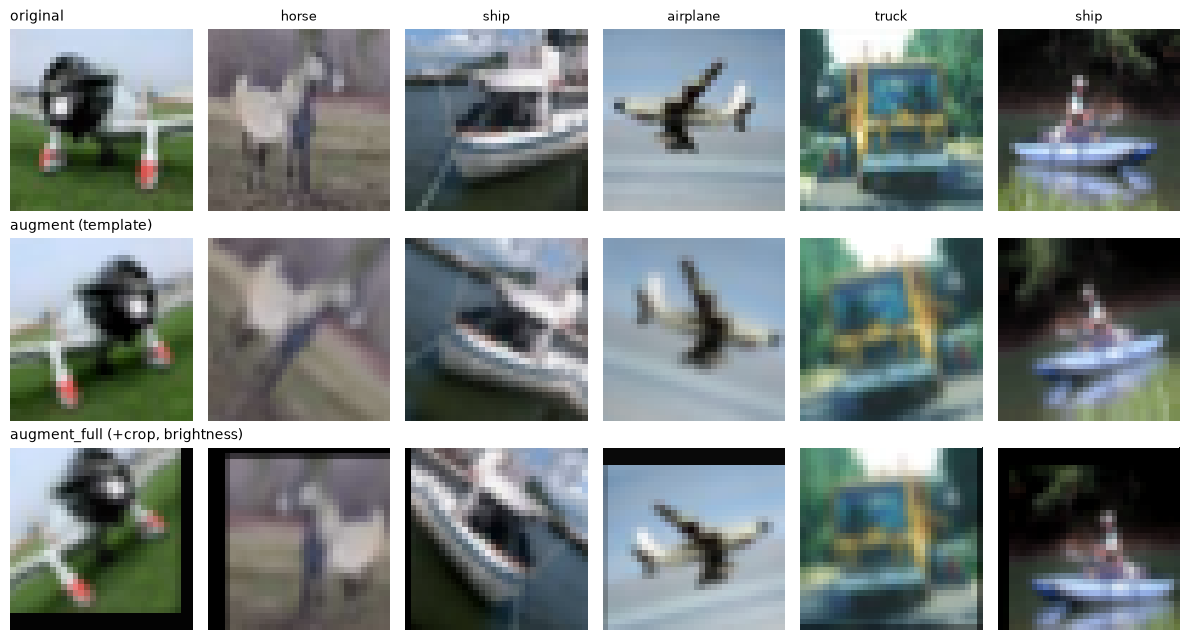

In [13]:
# To-Do: visualize a few augmented samples
import matplotlib.pyplot as plt
tf.keras.utils.set_random_seed(3)
idx = np.random.choice(len(x_tr32), 6, replace=False)          # 6 random training images
rows = [("original", lambda im: im),
        ("augment (template)", lambda im: augment(im, training=True)),
        ("augment_full (+crop, brightness)", lambda im: augment_full(im, training=True))]
plt.figure(figsize=(12, 6.5))
for r, (name, fn) in enumerate(rows):
    for i, k in enumerate(idx):
        img = x_tr32[k:k+1]                                     # keep the batch dimension: (1, 32, 32, 3)
        aug = np.clip(np.array(fn(img))[0], 0, 1)
        plt.subplot(3, 6, r * 6 + i + 1); plt.imshow(aug); plt.axis("off")
        if i == 0: plt.title(name, loc="left", fontsize=10)
        elif r == 0: plt.title(class_names[y_tr[k]], fontsize=9)
plt.tight_layout(); plt.show()

**What this shows:** the augmented images are still clearly the same objects (same class), but they are mirrored, slightly rotated, zoomed, shifted (black borders from the crop) or have a different contrast and brightness. In every epoch the network sees a new version of each image, so it is harder for it to memorize individual pictures.

**What this cell does:** builds and trains 4 identical small CNNs on the **same 5,000 training images**. The only difference between them is the augmentation (none / flip only / template `augment` / `augment_full`).
- **Small CNN on 32×32:** three blocks of `Conv2D` (learns local patterns with 3×3 filters, `padding="same"` keeps the size) + `MaxPooling2D` (halves height and width: 32→16→8→4), then `Flatten` → `Dense(128)` → `Dense(10, softmax)`. I use the original 32×32 images here (the template uses 96×96). The idea is the same, and on 32×32 it trains about 9× faster.
- The augmentation is put **inside the model**, as its first layer, so it is applied on the fly, to every batch, in every epoch.
- 15 epochs: augmentation usually needs more epochs than 3, because each epoch shows "new" images.
- I keep each history to compare the training and validation curves (overfitting).

In [14]:
# To-Do: build 2 models - baseline (no augmentation) and augmented (apply augment in the model)
def build_cnn_with_aug(aug_layer=None):
    inputs = layers.Input(shape=(32,32,3))
    x = aug_layer(inputs) if aug_layer is not None else inputs     # augmentation only if given
    for filters in (32, 64, 128):                                  # 3 conv blocks
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)                               # 32->16->8->4
    x = layers.Flatten()(x)                                        # 4*4*128 = 2048 numbers
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

aug_runs = {"no augmentation": None, "flip only": augment_flip,
            "augment (template)": augment, "augment_full": augment_full}
aug_hist, aug_res = {}, {}
for name, aug_layer in aug_runs.items():
    tf.keras.utils.set_random_seed(7)
    m = build_cnn_with_aug(aug_layer)
    h = m.fit(x_tr32, y_tr_oh, validation_split=0.1, epochs=15, batch_size=64, verbose=0)
    loss, acc = m.evaluate(x_te32, y_te_oh, verbose=0)
    aug_hist[name], aug_res[name] = h.history, {"test_acc": acc, "test_loss": loss,
                                                "final_train_acc": h.history["accuracy"][-1],
                                                "final_val_acc": h.history["val_accuracy"][-1]}
    if name == "no augmentation": m_base = m                       # keep the baseline model for Exercise 5
    print(f"{name:20s} train acc {h.history['accuracy'][-1]:.3f} | val acc {h.history['val_accuracy'][-1]:.3f} | test acc {acc:.3f} | test loss {loss:.3f}")

base_acc = float(aug_res["no augmentation"]["test_acc"])
aug_acc = float(aug_res["augment (template)"]["test_acc"])
print({"base_acc": base_acc, "aug_acc": aug_acc})

no augmentation      train acc 0.820 | val acc 0.446 | test acc 0.521 | test loss 1.948


flip only            train acc 0.717 | val acc 0.524 | test acc 0.536 | test loss 1.410


augment (template)   train acc 0.578 | val acc 0.458 | test acc 0.505 | test loss 1.488


augment_full         train acc 0.515 | val acc 0.466 | test acc 0.501 | test loss 1.477
{'base_acc': 0.5210000276565552, 'aug_acc': 0.5049999952316284}


**What this cell does:** plots the training accuracy (dashed) and validation accuracy (solid) per epoch for each run. The gap between the two lines is a direct picture of overfitting.

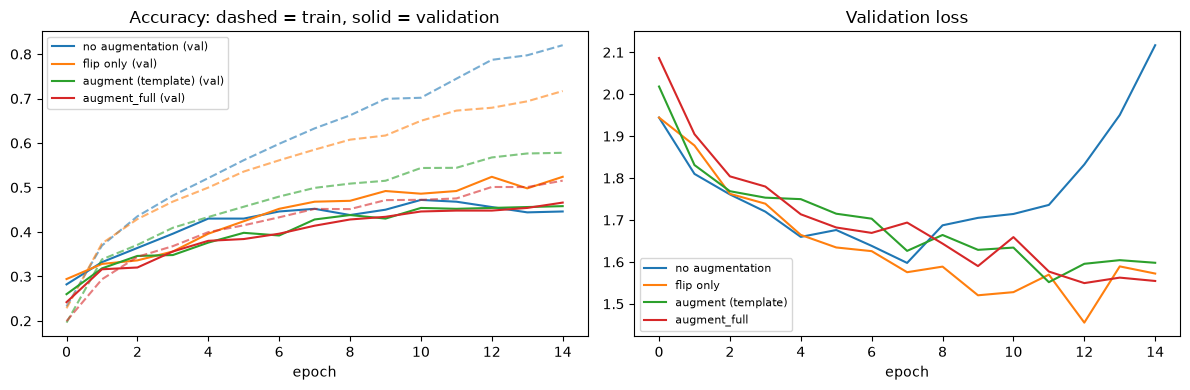

                    test_acc  test_loss  final_train_acc  final_val_acc  train - val gap
no augmentation        0.521      1.948            0.820          0.446            0.374
flip only              0.536      1.410            0.717          0.524            0.193
augment (template)     0.505      1.488            0.578          0.458            0.120
augment_full           0.501      1.477            0.515          0.466            0.049


In [15]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for name, h in aug_hist.items():
    line, = plt.plot(h["val_accuracy"], label=f"{name} (val)")
    plt.plot(h["accuracy"], ls="--", color=line.get_color(), alpha=0.6)
plt.title("Accuracy: dashed = train, solid = validation"); plt.xlabel("epoch"); plt.legend(fontsize=8)
plt.subplot(1, 2, 2)
for name, h in aug_hist.items():
    plt.plot(h["val_loss"], label=name)
plt.title("Validation loss"); plt.xlabel("epoch"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

aug_table = pd.DataFrame(aug_res).T.round(3)
aug_table["train - val gap"] = (aug_table["final_train_acc"] - aug_table["final_val_acc"]).round(3)
print(aug_table.to_string())

**What this shows:** the baseline without augmentation **overfits strongly**. Its training accuracy keeps climbing to 0.820 while validation stays around 0.45, and its **validation loss turns upward after epoch 8** (from about 1.6 to 2.1). That is the classic overfitting signature. Every augmented model has a **much smaller train–validation gap**: 0.374 without augmentation, 0.193 with flip only, 0.120 with the template pipeline and 0.049 with the full combination. Their validation loss stays around 1.5–1.6 instead of climbing, and the test loss falls from 1.948 to about 1.41–1.49. The **test accuracy**, however, only improved with **flip only (53.6% vs 52.1%)**. The two stronger pipelines ended slightly lower (50.5% and 50.1%). Their training accuracy (0.58 and 0.52) shows they are still **underfitting** after 15 epochs: a harder, more varied training task needs more epochs (or a bigger model) before the accuracy gain shows up.

**To-Do:** Write 3–5 sentences summarizing how augmentation changed generalization and when to adjust augmentation strength.

**My answer:** Augmentation clearly improved generalization **in terms of overfitting**: the gap between training and validation accuracy shrank from 0.37 (no augmentation) to 0.05 (full combination), and the test loss dropped from 1.95 to about 1.48. That means the predictions are better calibrated and much less overconfident on images the model has not seen. Each epoch shows a slightly different version of every image, so the network cannot memorize the 5,000 pictures and has to learn features that survive flips, rotations, shifts and colour changes. In my 15-epoch budget only **mild augmentation (horizontal flip) also raised test accuracy** (53.6% vs 52.1%). The stronger combinations made training so much harder that the model was still underfitting (training accuracy around 0.5). So augmentation strength should match the model and the training budget: increase it when the train–val gap is large (overfitting), reduce it, or train longer, when training accuracy stays low (underfitting). Also only use transformations that keep the label correct (a vertical flip would be wrong for digits like 6/9).

## Exercise 5: Model Performance Comparison with Advanced Techniques

**As stated in the exercise**  
Objective: Compare performance before and after applying advanced techniques.  

Instructions: Train a baseline model without advanced techniques. Apply at least two techniques such as tuning and augmentation. Train the improved model and evaluate on the same test set. Create a table or chart comparing accuracy and loss. Write a short reflection on the effectiveness.

**Guidance**  
Collect results consistently: same test split, identical metrics, and equal evaluation protocol.

**Learning point**  
Keep a fixed evaluation harness. Changing data or metrics confounds comparisons.

**What this cell does:** trains the **improved model**, which combines three techniques on the **same 5,000 training images**, and evaluates it on the **same 1,000 test images** as the baseline:
1. **Transfer learning:** the pre-trained MobileNetV2 base (a fresh copy), on the 96×96 images,
2. **Data augmentation:** the same 4 layers as the template's `augment` pipeline, as the first layer (rebuilt as `augment_96`, because a Keras `Sequential` remembers the 32×32 input size it was first called with in Exercise 4),
3. **Tuned training schedule:** the head is trained first with the base frozen (Adam 1e-3, 3 epochs), then the top 20 layers are fine-tuned at a 10× lower learning rate (1e-4, 3 epochs), plus a `Dropout(0.2)` in the head.

**Baseline:** the small CNN from Exercise 4 with no augmentation, no transfer learning and default Adam (`m_base`). Both models are evaluated with the same `evaluate` call on the same test set.

In [16]:
tf.keras.utils.set_random_seed(7)
base2 = tf.keras.applications.MobileNetV2(include_top=False, input_shape=(96,96,3), weights="imagenet")
base2.trainable = False

inputs = layers.Input(shape=(96,96,3))
# a fresh copy of the template's augment pipeline: a Keras Sequential remembers the image size it was
# first used with (32x32 in Exercise 4), so I rebuild the same 4 layers for the 96x96 input
augment_96 = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.1),
                                  layers.RandomZoom(0.1), layers.RandomContrast(0.1)], name="augment_96")
x = augment_96(inputs)                                                # technique 2: augmentation
x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
x = base2(x, training=False)                                          # technique 1: transfer learning
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
model_improved = models.Model(inputs, outputs)

# stage 1: frozen base, normal learning rate
model_improved.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model_improved.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=3, batch_size=128, verbose=2)
# stage 2: technique 3 - fine-tune the top 20 layers with a 10x lower learning rate
base2.trainable = True
for layer in base2.layers[:-20]:
    layer.trainable = False
model_improved.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
model_improved.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=3, batch_size=128, verbose=2)

imp_loss, imp_acc = model_improved.evaluate(x_te, y_te_oh, verbose=0)
base_loss_c, base_acc_c = m_base.evaluate(x_te32, y_te_oh, verbose=0)   # baseline on the same 1,000 test images
print({"baseline_cnn_test_acc": round(float(base_acc_c), 4), "improved_test_acc": round(float(imp_acc), 4)})

Epoch 1/3


36/36 - 7s - 182ms/step - accuracy: 0.4758 - loss: 1.4906 - val_accuracy: 0.7380 - val_loss: 0.7675


Epoch 2/3


36/36 - 3s - 81ms/step - accuracy: 0.6733 - loss: 0.9392 - val_accuracy: 0.7900 - val_loss: 0.6555


Epoch 3/3


36/36 - 3s - 78ms/step - accuracy: 0.7058 - loss: 0.8385 - val_accuracy: 0.7720 - val_loss: 0.6717


... (3 outputs left out)

36/36 - 4s - 109ms/step - accuracy: 0.7573 - loss: 0.6963 - val_accuracy: 0.7740 - val_loss: 0.7132


Epoch 3/3


36/36 - 4s - 98ms/step - accuracy: 0.8011 - loss: 0.5921 - val_accuracy: 0.7640 - val_loss: 0.7644


{'baseline_cnn_test_acc': 0.521, 'improved_test_acc': 0.767}


**What this cell does (Pre-filled chart, completed):** builds the comparison table with **accuracy and loss** for every model, and draws the bar chart from the template. The first table is the real before/after comparison, because all its models use the same CIFAR test images. The second chart also shows the MNIST and digits results from Exercises 1–2 for completeness. Those use different datasets, so they should not be compared with the CIFAR bars.

CIFAR-10 subset, same 1,000 test images:
                               model  test_acc  test_loss
        baseline CNN (no techniques)     0.521     1.9480
       CNN + augmentation (template)     0.505     1.4883
                  CNN + augment_full     0.501     1.4771
             transfer, frozen (Ex 3)     0.809     0.5665
         transfer + fine-tune (Ex 3)     0.797     0.7276
IMPROVED: transfer + aug + fine-tune     0.767     0.7994


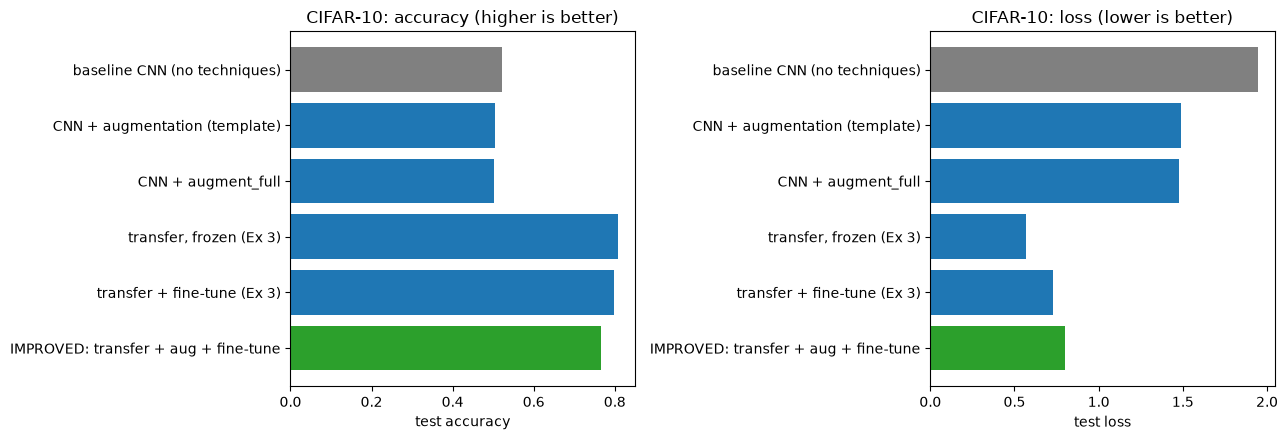

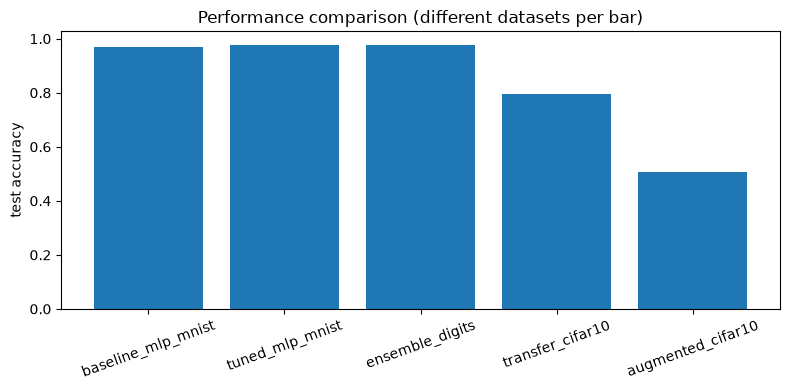

In [17]:
# Pre-filled: assembling a comparison table from your earlier results
cifar_results = pd.DataFrame([
    {"model": "baseline CNN (no techniques)",       "test_acc": float(base_acc_c), "test_loss": float(base_loss_c)},
    {"model": "CNN + augmentation (template)",      "test_acc": aug_acc, "test_loss": float(aug_res["augment (template)"]["test_loss"])},
    {"model": "CNN + augment_full",                 "test_acc": float(aug_res["augment_full"]["test_acc"]), "test_loss": float(aug_res["augment_full"]["test_loss"])},
    {"model": "transfer, frozen (Ex 3)",            "test_acc": float(frozen_acc), "test_loss": float(frozen_loss)},
    {"model": "transfer + fine-tune (Ex 3)",        "test_acc": float(test_acc_tl), "test_loss": float(test_loss_tl)},
    {"model": "IMPROVED: transfer + aug + fine-tune","test_acc": float(imp_acc), "test_loss": float(imp_loss)},
])
print("CIFAR-10 subset, same 1,000 test images:")
print(cifar_results.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(cifar_results["model"], cifar_results["test_acc"], color=["gray"] + ["tab:blue"] * 4 + ["tab:green"])
axes[0].set_xlabel("test accuracy"); axes[0].set_title("CIFAR-10: accuracy (higher is better)")
axes[1].barh(cifar_results["model"], cifar_results["test_loss"], color=["gray"] + ["tab:blue"] * 4 + ["tab:green"])
axes[1].set_xlabel("test loss"); axes[1].set_title("CIFAR-10: loss (lower is better)")
for ax in axes: ax.invert_yaxis()
plt.tight_layout(); plt.show()

results = [
    {"model": "baseline_mlp_mnist", "test_acc": float(base_test[1])},
    {"model": "tuned_mlp_mnist", "test_acc": float(test_acc)},  # from Exercise 1
    {"model": "ensemble_digits", "test_acc": float(best_ens_acc)},              # from Exercise 2
    {"model": "transfer_cifar10", "test_acc": float(test_acc_tl)},             # from Exercise 3
    {"model": "augmented_cifar10", "test_acc": aug_acc},            # from Exercise 4
]
# Simple bar chart
labels = [r["model"] for r in results]
vals = [r["test_acc"] for r in results]
plt.figure(figsize=(8,4))
plt.bar(range(len(vals)), vals)
plt.xticks(range(len(vals)), labels, rotation=20)
plt.ylabel("test accuracy")
plt.title("Performance comparison (different datasets per bar)")
plt.tight_layout()
plt.show()

**What this shows:** on the same 1,000 CIFAR-10 test images, the **improved model (transfer learning + augmentation + fine-tuning at a lower learning rate) reaches 76.7% accuracy and a loss of 0.799**, against **52.1% and 1.948 for the baseline CNN**. That is +24.6 points of accuracy and a loss 2.4× lower. But the table also shows that the best model of all is the **simplest transfer setup: frozen MobileNetV2 with only the head trained (80.9%, loss 0.567)**. Adding fine-tuning (79.7%) or fine-tuning plus augmentation (76.7%) did not beat it within this short training budget. The last chart puts the results of all exercises side by side, but its bars come from three different datasets (MNIST, digits, CIFAR-10), so only the CIFAR bars can be compared with each other.

**To-Do:** Write 3–5 sentences reflecting on which techniques delivered the largest gains and why.

**My answer:** **Transfer learning delivered by far the largest gain:** from 52.1% to 80.9% test accuracy on the same CIFAR-10 test set, with fewer epochs, because the pre-trained ImageNet features are much richer than what a small CNN can learn from 5,000 images. Data augmentation had a smaller effect: on the small CNN it cut overfitting a lot (train–val gap from 0.37 to 0.05–0.19, test loss from 1.95 to about 1.4–1.5), but it only raised accuracy in the mild flip-only version. Combining techniques was **not automatically better**. The "improved" model with transfer learning + augmentation + fine-tuning (76.7%) beat the baseline by 24.6 points, but stayed below plain frozen transfer learning (80.9%), because with only 6 epochs the augmented model was still learning (training accuracy 0.80) and fine-tuning on few images tends to overfit. On MNIST, tuning gave a small but real gain (97.45% → 97.84% at equal epochs). The lesson is to add one technique at a time, measure it on a fixed test set, and give the harder setups (augmentation, fine-tuning) enough epochs before judging them.